<a href="https://colab.research.google.com/github/sonyxoxo/ipd/blob/main/%D0%92%D0%B8%D0%B7%D1%83%D0%B0%D0%BB%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D1%8D%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BF%D0%BE%D1%82%D1%80%D0%B5%D0%B1%D0%BB%D0%B5%D0%BD%D0%B8%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Этап 4. Визуализация электропотребления

Данные берутся из `data/raw` внутри клона GitHub. Профили считаются по исходным минутным значениям, а не из повторно загружаемых ZIP предыдущих этапов.

## Имена переменных

- `source` — выбранный исходный файл; `measurements` — прочитанные измерения в `pandas`.
- `minutes` — равномерная минутная сетка; `month_ids` — коды выбранных месяцев в формате `YYYY-MM`.
- `profile_table` — по 1440 минут суточного профиля каждого месяца.
- `minute_of_day` — номер минуты суток от 0 (00:00) до 1439 (23:59).
- `mean_kw` — средняя мощность по дням для этой минуты суток, в кВт.
- `n_observed` — число дней, для которых измерение этой минуты известно.
- `n_expected` — число ожидаемых измерений этой минуты внутри исследуемого периода.
- `coverage_pct` — полнота этой минуты: `100 × n_observed / n_expected`, в процентах.
- `labplot_table` — таблица для LabPlot: `Hour` — время суток в часах; `P_YYYY-MM_kW` — средняя мощность месяца; `Coverage_YYYY-MM_pct` — полнота месяца.

Месяцы 2008 года используются, если они есть в источнике. Для другого файла автоматически берутся первые доступные месяцы; называть их всеми сезонами года без проверки **нельзя**.

In [1]:
# Одна настройка пути к репозиторию. Исходные файлы не загружаются вручную.
from pathlib import Path
import subprocess
import sys

repo_dir = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ipd_analysis.py").is_file()), None)
if repo_dir is None:
    repo_dir = Path("/content/ipd")
    if not (repo_dir / "ipd_analysis.py").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/sonyxoxo/ipd.git", str(repo_dir)], check=True)
sys.path.insert(0, str(repo_dir))

from ipd_analysis import choose_source, load_measurements, regular_minutes, result_folder, save_csv, save_run_metadata

# Если в data/raw несколько файлов, задайте относительный путь явно:
# source = choose_source("data/raw/household_power_consumption.zip")
source = choose_source()
measurements = load_measurements(source)  # Один pd.read_csv на весь ноутбук.
output_dir = result_folder(source)
output_dir.mkdir(parents=True, exist_ok=True)
print("Источник:", source)
print("Строк:", len(measurements))

Источник: /content/ipd/data/raw/household_power_consumption.zip
Строк: 2075259


## Расчёт суточных профилей и файл LabPlot

`select_months()` выбирает существующие месяцы. `daily_profiles()` создаёт 1440 минут каждого выбранного месяца с правильным учётом отсутствующих строк. `export_labplot()` формирует широкий формат, который удобно импортировать в LabPlot.

**Важно:** если какие-то минуты вообще не наблюдались, соответствующее среднее будет `NaN`, а не нулём.

In [2]:
from ipd_analysis import select_months, daily_profiles, export_labplot

minutes = regular_minutes(measurements)
month_ids = select_months(minutes)
profile_table = daily_profiles(minutes, month_ids)
labplot_table = export_labplot(profile_table)
display(profile_table.head())
save_csv(profile_table, output_dir / "04_daily_profiles.csv")
save_csv(labplot_table, output_dir / "04_labplot_profiles.csv")
print("Месяцы:", month_ids)

,month,minute_of_day,mean_kw,median_kw,q1_kw,q3_kw,n_observed,n_expected,coverage_pct,iqr_kw
0,2008-01,0,0.955935,0.540,0.331,1.379,31,31,100.0,1.048
1,2008-01,1,0.945935,0.492,0.329,1.383,31,31,100.0,1.054
2,2008-01,2,0.948903,0.622,0.347,1.379,31,31,100.0,1.032
3,2008-01,3,1.000516,0.664,0.378,1.375,31,31,100.0,0.997
4,2008-01,4,1.011613,0.668,0.382,1.471,31,31,100.0,1.089


Месяцы: ['2008-01', '2008-04', '2008-07', '2008-09']


## Графики мощности и полноты

- `chart_path` — путь к изображению PNG в папке результатов этого исходного файла.
- На верхнем графике — средняя активная мощность, **кВт**; на нижнем — полнота, **%**. Различные единицы не смешиваются.
- `daily_chart_path` — график одного фактически наблюдавшегося дня.
- `missing_chart_path` — график недели вокруг самой длинной серии пропусков.
- `month_chart_path` — сравнение двух месяцев, включая различие в полноте наблюдений.
- Графики сохраняются в папку репозитория `результаты/…`, а не в архивы из Colab.

Графики сохранены в: /content/ipd/результаты/household_power_consumption-b916e64b


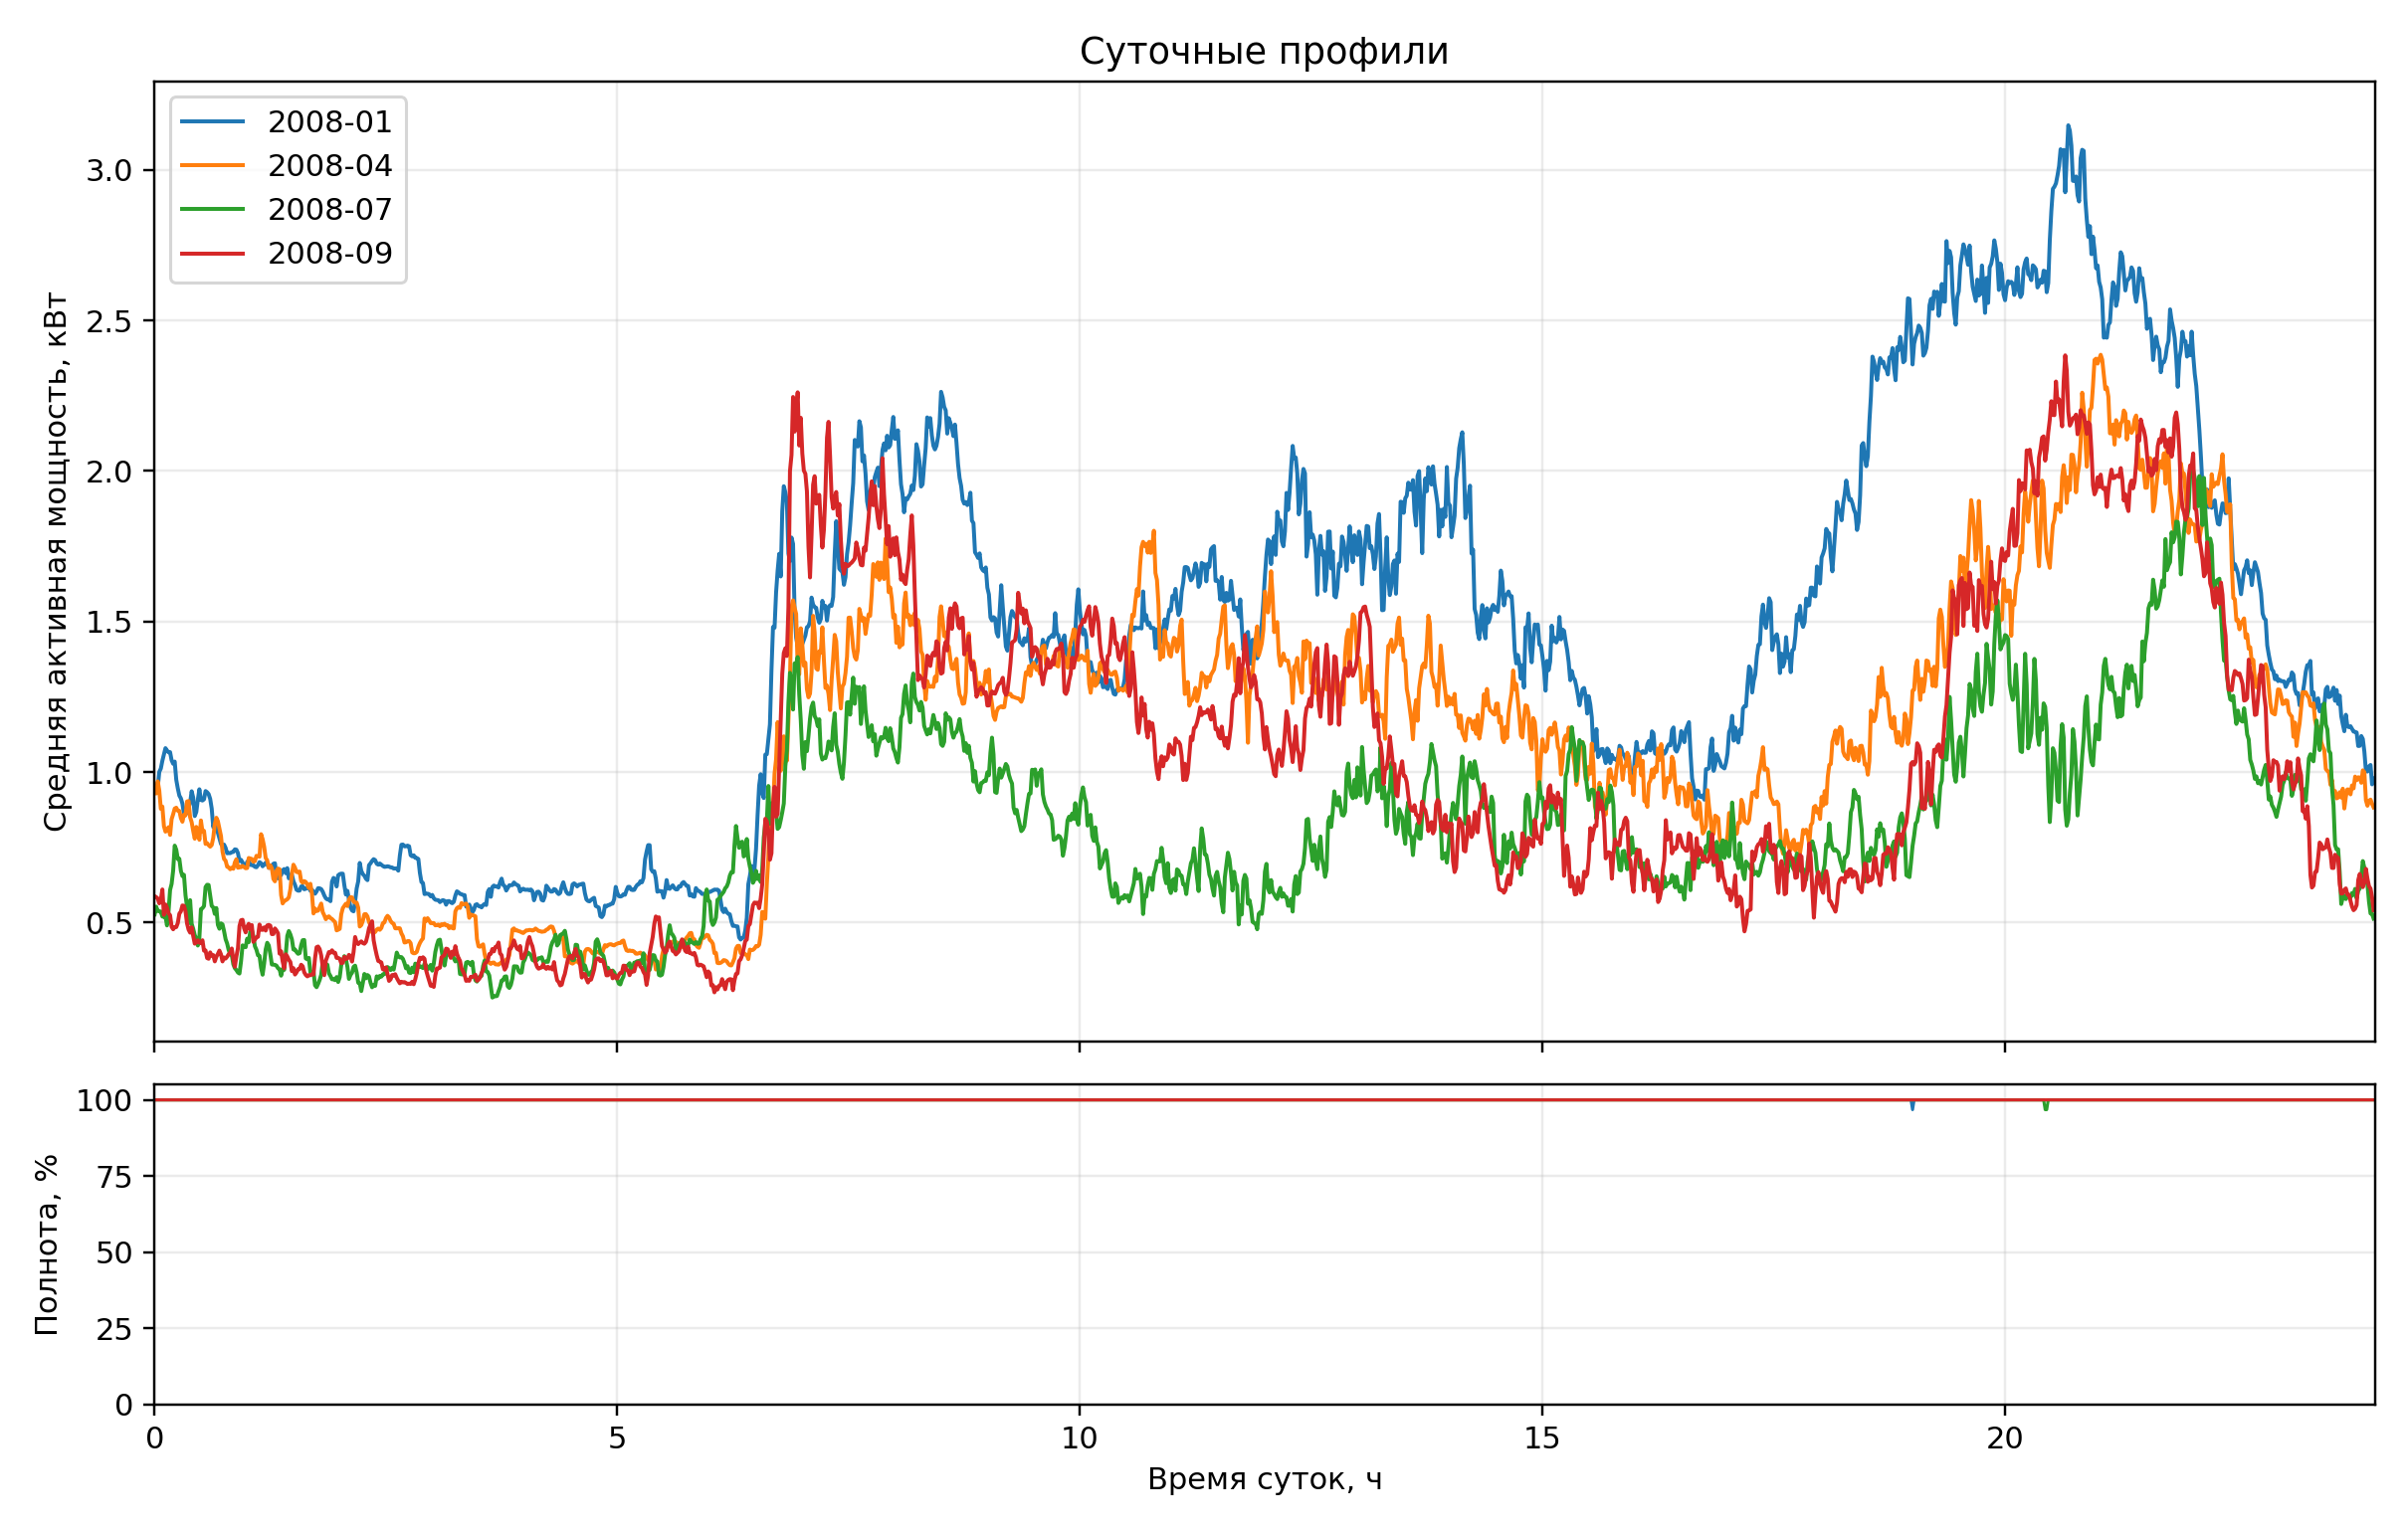

In [3]:
from run_analysis import plot_profiles, plot_one_day, plot_missing_week, plot_month_comparison

chart_path = output_dir / "04_daily_profiles.png"
daily_chart_path = output_dir / "04_one_day.png"
missing_chart_path = output_dir / "04_missing_week.png"
month_chart_path = output_dir / "04_month_comparison.png"
plot_profiles(profile_table, chart_path)
plot_one_day(minutes, daily_chart_path)
plot_missing_week(minutes, missing_chart_path)
plot_month_comparison(minutes, month_chart_path)
print("Графики сохранены в:", output_dir)
from IPython.display import Image, display
display(Image(filename=str(chart_path)))

## Воспроизводимость результата

Последняя ячейка сохраняет `metadata.json` с SHA-256 исходного файла, хешами исполняемого кода, версиями библиотек и датой запуска. Поэтому любой результат можно связать с конкретным источником и версией обработки.

In [4]:
save_run_metadata(source, output_dir, {"notebook": 'Визуализация_электропотребления.ipynb'})

PosixPath('/content/ipd/результаты/household_power_consumption-b916e64b/metadata.json')